# 02 — Choosing a target variable

The modelling outcome remains auction shares. A transformed target determines what the fitted model learns before we reconstruct those shares. We compare all thirteen targets already studied, then retain two finalists for detailed comparison.

Let $A_t$ be today's auction volume, $M_{20,t}$ its stock's median over the previous 20 stock rows, and $A_{t-1}$ the preceding stock row's auction volume.

- The current target is $r_t=\log(1+A_t)-\log(1+M_{20,t})$.
- The growth finalist is $g_t=\log(1+A_t)-\log(1+A_{t-1})$.

Both remove a stock-specific scale. The median uses several preceding observations and is less sensitive to one exceptional prior auction. Log growth responds directly to yesterday's auction and can reverse sharply after a spike.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


## Build historical references from raw data

Windows end at the previous row within PERMNO. The 20-row window can contain fewer than 20 observed auctions because SQL aggregates skip missing values. The preceding-row lag can itself be missing. We build windows before selecting eligible outcome rows, preserving the history convention used in the experiments. The supplied anomaly is excluded as a supervised label. Historical feature calculations retain the existing project's treatment of that source row.

In [2]:
con.execute(f"""
CREATE TEMP TABLE target_panel AS
WITH joined AS (
    SELECT c.date, c.permno, c.ticker, c.daily_volume,
           a.auction_volume, coalesce(a.target_found, false) AS target_found
    FROM read_parquet('{CRSP}', union_by_name=true) c
    LEFT JOIN read_parquet('{AUCTION}', union_by_name=true) a USING (date, permno)
), history AS (
    SELECT *, lag(auction_volume) OVER w AS lag1_auction_volume,
           median(auction_volume) OVER w20 AS median20_auction_volume,
           median(auction_volume) OVER w60 AS median60_auction_volume,
           avg(auction_volume) OVER w20 AS avg20_auction_volume,
           avg(auction_volume) OVER w60 AS avg60_auction_volume,
           avg(daily_volume) OVER w20 AS avg20_daily_volume
    FROM joined
    WINDOW w AS (PARTITION BY permno ORDER BY date),
           w20 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING),
           w60 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 60 PRECEDING AND 1 PRECEDING)
)
SELECT h.*, ln(1 + auction_volume) AS log1p_auction_volume,
       target_found AND auction_volume IS NOT NULL
       AND NOT coalesce(an.exclude_from_model, false) AS eligible_target
FROM history h LEFT JOIN read_parquet('{ANOMALIES}') an USING (date)
WHERE h.date >= DATE '2015-01-01'
""")
display(sql("SELECT count(*) AS stock_days, sum(eligible_target::INT) AS eligible_labels FROM target_panel"))
assert sql("SELECT count(*)-count(DISTINCT(date,permno)) AS duplicates FROM target_panel").duplicates.iloc[0] == 0

,stock_days,eligible_labels
0,3594404,"3,499,401.0000"


In [3]:
from notebooks.compare_ridge_targets import TARGETS, transform, invert
labels = pd.DataFrame([
    {'target': name, 'transformation': definition[2]}
    for name, definition in TARGETS.items()
])
display(labels)
sample = sql("""
    SELECT * FROM (SELECT * FROM target_panel WHERE eligible_target)
    USING SAMPLE 200000 ROWS (reservoir, 42)
""")
references = sorted({definition[1] for definition in TARGETS.values() if definition[1]})
observed = sample.dropna(subset=references).copy()
observed = observed[(observed[references] > 0).all(axis=1)]
fallbacks = dict.fromkeys(references, np.nan)
values = pd.DataFrame({name: transform(observed, name, fallbacks) for name in TARGETS})
display(values.quantile([.01, .25, .5, .75, .99]).T.rename_axis('target'))
print(f"Descriptive common-reference sample: {len(observed):,} of {len(sample):,} eligible sampled stock-days.")

,target,transformation
0,raw_volume,A
1,sqrt_volume,sqrt(A)
2,log_volume,log1p(A)
3,lag1_log_growth,log1p(A) - log1p(lag1 auction)
4,lag1_pct_growth,A / lag1 auction - 1 (simple growth rate)
5,median20_log_residual,log1p(A) - log1p(median20 auction); current ta...
6,median60_log_residual,log1p(A) - log1p(median60 auction)
7,mean20_log_residual,log1p(A) - log1p(mean20 auction)
8,mean60_log_residual,log1p(A) - log1p(mean60 auction)
9,median20_ratio,A / median20 auction


,0.0100,0.2500,0.5000,0.7500,0.9900
target,,,,,
raw_volume,281.0000,"18,511.0000","55,462.0000","163,117.0000","2,088,636.8000"
sqrt_volume,16.7631,136.0551,235.5037,403.8775,"1,445.2117"
log_volume,5.6419,9.8262,10.9235,12.0022,14.5520
lag1_log_growth,-2.3546,-0.4017,-0.0075,0.3965,2.4031
lag1_pct_growth,-0.9055,-0.3309,-0.0074,0.4867,10.0847
median20_log_residual,-1.2416,-0.3026,0.0040,0.3629,2.3909
median60_log_residual,-1.2570,-0.2931,0.0185,0.3879,2.4423
mean20_log_residual,-2.2751,-0.6229,-0.2544,0.1204,2.0388
mean60_log_residual,-2.3582,-0.6721,-0.3106,0.0667,1.9960


Descriptive common-reference sample: 198,927 of 200,000 eligible sampled stock-days.


## Why the 20-day median is a useful anchor

Compare correlation in raw shares and log shares, rank correlation, and association after demeaning within each stock. A high pooled correlation partly reflects persistent differences between large and small stocks. The within-stock measure asks whether the historical median also tracks changes in a given stock's auction level.

,rows,raw_Pearson,log_Pearson,Spearman,within_stock_log_Pearson
reference,,,,,
lag1_auction_volume,198927,0.3024,0.8903,0.8799,0.5801
median20_auction_volume,199821,0.5398,0.9277,0.9196,0.6798
avg20_auction_volume,199821,0.5202,0.9081,0.8974,0.6027


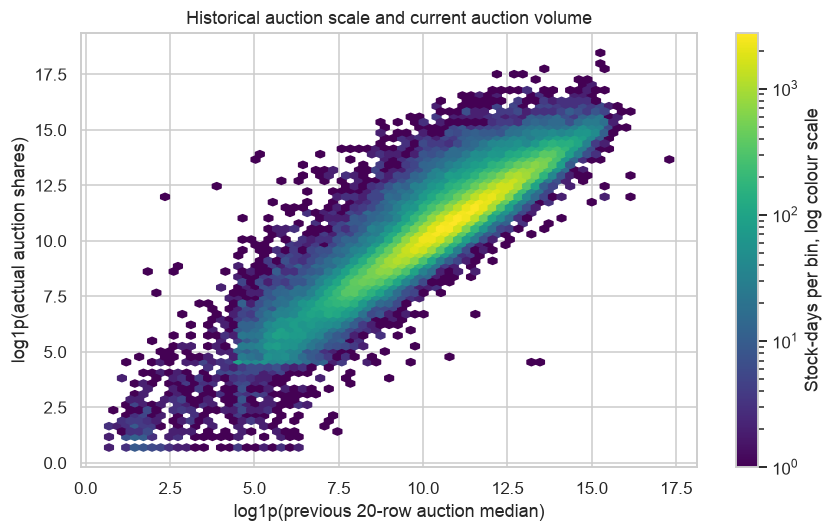

In [4]:
correlations = []
for ref in ['lag1_auction_volume', 'median20_auction_volume', 'avg20_auction_volume']:
    part = sample[['permno', 'auction_volume', ref]].dropna()
    y = np.log1p(part.auction_volume)
    x = np.log1p(part[ref])
    within_x = x - x.groupby(part.permno).transform('mean')
    within_y = y - y.groupby(part.permno).transform('mean')
    correlations.append({'reference': ref, 'rows': len(part),
        'raw_Pearson': part[ref].corr(part.auction_volume),
        'log_Pearson': x.corr(y), 'Spearman': x.rank().corr(y.rank()),
        'within_stock_log_Pearson': within_x.corr(within_y)})
display(pd.DataFrame(correlations).set_index('reference'))
fig, ax = plt.subplots(figsize=(8, 5))
part = sample.dropna(subset=['median20_auction_volume'])
plot = ax.hexbin(np.log1p(part.median20_auction_volume), np.log1p(part.auction_volume),
                 gridsize=65, mincnt=1, bins='log', cmap='viridis')
ax.set(xlabel='log1p(previous 20-row auction median)', ylabel='log1p(actual auction shares)',
       title='Historical auction scale and current auction volume')
fig.colorbar(plot, ax=ax, label='Stock-days per bin, log colour scale')
plt.tight_layout(); plt.show()

Proof Trading describes using the previous 20 days' median auction size as a default prediction in its own forecasting evaluation. That establishes practitioner use. Our own evidence combines a strong historical relationship with chronological forecast comparisons. The published project relationship study reports pooled log Pearson correlation of **0.9284**, Spearman correlation of **0.9211**, and within-stock log Pearson correlation of **0.6818**. The freshly sampled table above can differ slightly. [Proof Trading, August 3, 2026](https://medium.com/prooftrading/predicting-the-closing-auction-volume-a-data-science-odyssey-f82f54e8767a)

The phrase **industry-used benchmark** describes the evidence available here. A market-wide adoption claim would require broader documentation.

## Distribution and stability

The plots compare native target units. Raw and square-root distributions use their central 99% for the displayed horizontal range. This plotting choice does not remove observations from the saved forecast comparisons. The log residuals can be negative when the actual auction is below its historical reference.

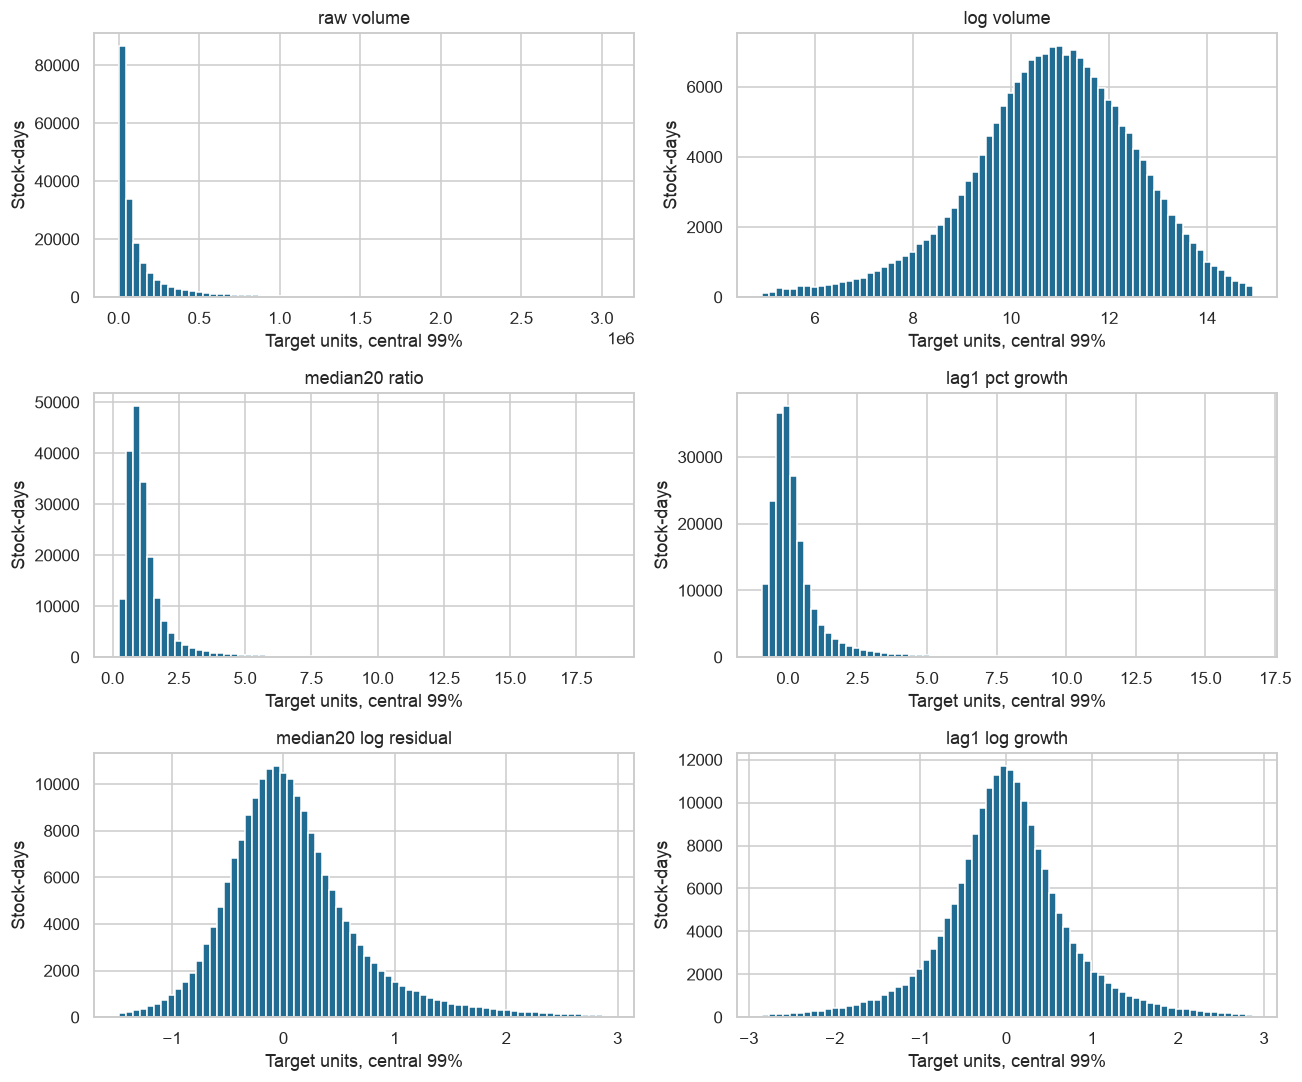

,target,stocks,median_absolute_level_shift_in_2022_iqrs,median_2025_to_2022_iqr_ratio,median_lag1_correlation,stationary_compatible_rate
0,raw_volume,1003,1.3788,1.6653,0.0899,0.2323
1,sqrt_volume,1003,1.2204,1.2538,0.2505,0.0967
2,log_volume,1003,1.0650,0.9429,0.3937,0.0588
3,median20_log_residual,1003,0.0367,0.9199,0.2251,0.9900
4,median60_log_residual,1003,0.0665,0.9363,0.2502,0.9571
5,mean20_log_residual,1003,0.0988,0.8906,0.2913,0.9332
6,mean60_log_residual,1003,0.1676,0.9109,0.2893,0.7707
7,adv20_log_residual,1003,0.5446,0.8965,0.3311,0.1416
8,median20_share_residual,1003,0.0501,1.6216,0.0508,0.9093
9,median20_ratio,1003,0.0350,0.9159,0.0542,0.9462


In [5]:
selected = ['raw_volume', 'log_volume', 'median20_ratio', 'lag1_pct_growth',
            'median20_log_residual', 'lag1_log_growth']
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for name, ax in zip(selected, axes.flat):
    v = values[name]
    low, high = v.quantile([.005, .995])
    ax.hist(v[(v >= low) & (v <= high)], bins=70, color='#216c93')
    ax.set(title=name.replace('_', ' '), ylabel='Stock-days', xlabel='Target units, central 99%')
plt.tight_layout(); plt.show()

stability = saved('experiments/21_ridge_target_definitions/target_stability.csv')
stationarity = saved('experiments/21_ridge_target_definitions/target_stationarity_summary.csv')
diagnostics = stability.merge(stationarity[['target', 'stationary_compatible_rate']], on='target')
display(diagnostics[['target', 'stocks', 'median_absolute_level_shift_in_2022_iqrs',
                     'median_2025_to_2022_iqr_ratio', 'median_lag1_correlation',
                     'stationary_compatible_rate']])

These saved stability diagnostics use 1,003 stocks observed on every one of 1,003 sessions in 2022–2025. They favor continuously covered securities. ADF rejection together with KPSS non-rejection is compatible with stationarity for **99.0%** of those stocks under the current target and **97.3%** under log growth. The tests assess particular statistical assumptions, and all percentages are descriptive across dependent stock series. Both finalists remove much of the level drift present in direct log volume.

Log growth has a median lag-one correlation around **−0.459**, consistent with reversal following an exceptional prior day. The median-relative residual retains milder positive dependence around **0.225**.

## Compare forecast performance in the same units

Training errors for raw shares and log residuals have different units. The saved ridge experiment reconstructs auction shares for all thirteen targets and evaluates them on the same 1,271,378 eligible stock-days over 2022–2025. Each candidate uses the same 58 source features and historical samples. The table below fixes penalty selection to historical log RMSE and applies common bounds.

Log RMSE measures typical proportional forecast accuracy. WAPE weights absolute share errors by total observed shares. Raw-share RMSE emphasizes very large misses. Signed bias records aggregate over- or underprediction. Development values average annual 2022–2024 metrics equally. The previously inspected 2025 period is reported separately.

,rmse_log,wape,rmse_raw,aggregate_bias
target,,,,
median20_log_residual,0.4881,0.3674,"657,159.7618",-0.1450
median60_log_residual,0.4882,0.3676,"657,301.5991",-0.1449
mean20_log_residual,0.4891,0.3681,"657,268.6946",-0.1462
mean60_log_residual,0.4892,0.3672,"656,867.1948",-0.1461
lag1_log_growth,0.4910,0.3743,"659,832.0911",-0.1480
log_volume,0.4965,0.3704,"659,994.6131",-0.1548
adv20_log_residual,0.4972,0.3717,"659,823.6955",-0.1523
median20_ratio,0.7560,0.5431,"710,191.2885",0.0741
adv20_ratio,0.9222,0.5700,"730,259.8120",0.0167


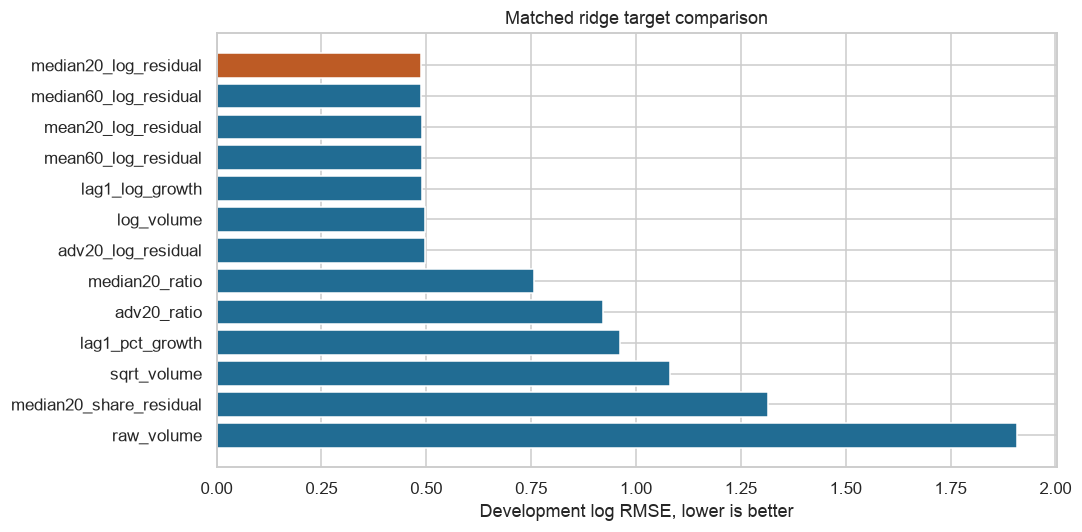

In [6]:
results = saved('experiments/21_ridge_target_definitions/development_metrics.csv')
comparison = results.query("selection == 'log_rmse' and bounds_policy == 'common_bounds'")
comparison = comparison.sort_values('rmse_log')
display(comparison[['target', 'rmse_log', 'wape', 'rmse_raw', 'aggregate_bias']].set_index('target'))
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#bd5b25' if n == 'median20_log_residual' else '#216c93' for n in comparison.target]
ax.barh(comparison.target, comparison.rmse_log, color=colors)
ax.invert_yaxis()
ax.set(xlabel='Development log RMSE, lower is better', title='Matched ridge target comparison')
plt.tight_layout(); plt.show()

In [7]:
controlled = saved('experiments/17_target_formulations/target_comparison_summary.csv')
display(controlled)

,candidate,family,target,development_rmse_log,development_wape,development_bias,development_log_mae,confirmation_rmse_log,confirmation_wape,confirmation_bias,mean_difference,ci_2_5,ci_97_5,rmse_change_vs_same_family_median,stable_development_years,target_change_passes_gate
0,historical_frozen_ridge,historical_reference,median20_log_residual,0.4876,0.3680,-0.1438,0.3377,0.4451,0.3456,-0.0962,NaN,NaN,NaN,NaN,NaN,NaN
1,lgbm__lag1_log_growth,lgbm,lag1_log_growth,0.4703,0.3534,-0.1606,0.3303,0.4300,0.3284,-0.0966,-0.0007,-0.0018,0.0002,0.0009,False,False
2,lgbm__log_level,lgbm,log_level,0.4707,0.3569,-0.1605,0.3304,0.4300,0.3333,-0.0872,-0.0006,-0.0018,0.0005,0.0013,False,False
3,lgbm__median20_log_residual,lgbm,median20_log_residual,0.4694,0.3545,-0.1440,0.3310,0.4306,0.3294,-0.0890,0.0000,0.0000,0.0000,0.0000,True,False
4,ridge__lag1_log_growth,ridge,lag1_log_growth,0.4906,0.3742,-0.1485,0.3392,0.4488,0.3500,-0.1042,0.0014,0.0011,0.0018,0.0029,False,False
5,ridge__log_level,ridge,log_level,0.4965,0.3706,-0.1537,0.3413,0.4504,0.3491,-0.1125,0.0035,0.0033,0.0038,0.0087,False,False
6,ridge__median20_log_residual,ridge,median20_log_residual,0.4878,0.3674,-0.1452,0.3378,0.4468,0.3451,-0.0965,0.0000,0.0000,0.0000,0.0000,True,False


## Select the current target and retain log growth as the challenger

The matched ridge table favors the **20-day-median log residual** at roughly **0.4881** development log RMSE, compared with **0.4910** for log growth. A separate controlled LightGBM comparison also favors the median residual, at **0.46941 versus 0.47029**. Log growth is a strong alternative whose normalisation and stability warrant retaining it in the research story. The saved target-change experiments kept the current target under their adoption criteria.

The median supplies a robust historical scale, practitioner precedent, stable within-stock behaviour and the strongest development log RMSE among the tested ridge targets. Target selection is supported jointly by those observations.

For a residual prediction $\hat r_t$, reconstruct shares with

$$\hat A_t = \max\{0,\exp[\log(1+M_{20,t})+\hat r_t]-1\}.$$

Log growth uses the same inverse transformation with the prior auction as reference. When that reference is unavailable, fit the fallback on historical training labels. Empirical forecast bounds are also fitted historically. The next cell checks the transformation and inverse on observed-reference rows without imposing forecast bounds.

In [8]:
for name in ['median20_log_residual', 'lag1_log_growth']:
    z = transform(observed, name, fallbacks)
    reconstructed = invert(z, observed, name, fallbacks)
    np.testing.assert_allclose(reconstructed, observed.auction_volume, rtol=1e-10, atol=1e-6)
assert len(comparison) == 13
print('All 13 target definitions are represented. Both finalist inverse transformations verified.')
con.close()
work.cleanup()

All 13 target definitions are represented. Both finalist inverse transformations verified.


Saved numerical evidence comes from `outputs/experiments/21_ridge_target_definitions` and `outputs/experiments/17_target_formulations`. The target histograms and correlation table are recomputed directly from raw data in this notebook. The stationarity and model tables display the completed historical studies.

Continue to [03 — Features and transformations](03_features_and_transformations.ipynb).